# Denoising autoencoder (BTXRD, deep learning)
Cleans every X-ray with a **denoising autoencoder**, a deep learning denoiser, **at its full size** (2440 x 2440), and only then makes it 512 x 512 (the same way as notebook 07). Everything else is the same as in the classical notebooks.
The new images are saved as PNG in **`BTXRD_autoencoder_512.zip`**. Inside the zip are the same `train`, `validation` and `test` folders, each with `normal` and `tumor`, as in `BTXRD_512.zip`. Every image stays in the same split as before. The original data is only read, never changed.

**A denoising autoencoder** squeezes the image into a smaller form and rebuilds it. It is trained by adding noise to images and teaching it to give back the image without the noise. The network is the convolutional denoising autoencoder of **Gondara (2016)**, *Medical image denoising using convolutional denoising autoencoders* (arXiv:1608.04667), which was tested on mammograms and dental X-rays. Its layers come from the paper's Figure 5: 5 convolutions with 64 filters, made 2 times smaller (max pooling) and 2 times bigger again (upsampling). The paper does not give the filter size, activations, loss or optimizer, so this notebook uses common choices: 3 x 3 filters, ReLU, a sigmoid at the end (pixels 0-1), MSE loss and Adam.

There is no ready-made trained model, so it is trained here first:
- **Only on the train images.** Squares of 128 x 128 pixels are cut from the full-size X-rays (only where the X-ray is, not the black square), and Gaussian noise of a random strength (0-25 gray levels) is added. The network learns to remove it.
- **The validation images** (with fixed noise) decide when to stop, like early stopping in the training notebooks. **The test images are never used for training.**
- The best model is saved in Drive (`BTXRD/denoising_autoencoder.pt`). If it is already there, it is loaded instead of trained again (set `RETRAIN = True` to train again).

Time: cutting the squares about 5 minutes, training about 10-30 minutes, then the images about 20-40 minutes on a T4 GPU.
## Before you run
1. **Make `BTXRD_full.zip` on your Mac** (only once, both notebooks use it): it must hold the folders `train`, `validation`, `test` and `Annotations` from `data/BTXRD no duplicates`. In Finder, select these 4 folders, right-click, *Compress*, and rename `Archive.zip` to `BTXRD_full.zip`.
2. **In Google Drive**, make a folder `BTXRD` (in *My Drive*) and upload `BTXRD_full.zip` and `BTXRD_512.zip` into it.
3. **In Colab**: *Runtime > Change runtime type > T4 GPU*, then *Run all*, and allow access to Google Drive.
4. **If Colab disconnects**, just *Run all* again: every finished image is already saved in Drive (folder `BTXRD/BTXRD_autoencoder_512`) and is skipped.
5. **At the end**, download `BTXRD_autoencoder_512.zip` and `BTXRD_autoencoder_512_full_size_scores.csv` (last cell, or from the Drive folder `BTXRD`) and put them in this folder, next to this notebook. Then save this notebook with its outputs: *File > Download > Download .ipynb*.

## Settings

In [2]:
import io
import json
import os
import shutil
import time
import zipfile
from collections import Counter
from pathlib import Path

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"           # needed for repeatable GPU results (set before torch starts)

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from google.colab import drive, files

drive.mount("/content/drive")
DRIVE = Path("/content/drive/MyDrive/BTXRD")               # your Google Drive folder with the 2 zips
FULL_ZIP = DRIVE / "BTXRD_full.zip"                        # the full-size images: train, validation, test, Annotations (only read)
OLD_ZIP_DRIVE = DRIVE / "BTXRD_512.zip"                    # the baseline zip (only read)
LOCAL = Path("/content/btxrd_full")                        # the full-size images are unzipped here (the fast local disk)
OLD_ZIP = Path("/content/BTXRD_512.zip")                   # a local copy of the baseline zip
NAME = "BTXRD_autoencoder_512"                             # the name of the new zip and of the folder inside it
OUT_DIR = DRIVE / NAME                                     # the finished 512 x 512 PNGs, kept in Drive, so a disconnect loses nothing
NEW_ZIP = Path("/content") / (NAME + ".zip")               # the new zip, made at the end (and copied to Drive)
SPLITS = ["train", "validation", "test"]
MALIGNANT = {"osteosarcoma", "other mt"}               # all other tumor types are benign

SIZE = (512, 512)    # the same size as the baseline
PATCH = 128                  # autoencoder training: squares of 128 x 128 pixels, cut from the full-size X-rays
TRAIN_PATCHES_PER_IMAGE = 16 # squares per train image
VAL_PATCHES_PER_IMAGE = 4    # squares per validation image
SIGMA_MAX = 25               # training noise: Gaussian, a random strength from 0 to 25 gray levels for every square
EPOCHS = 50                  # the most rounds through all training squares (can stop earlier, see PATIENCE)
BATCH_SIZE = 64              # squares per training step
LEARNING_RATE = 0.001        # Adam
PATIENCE = 5                 # stop early if the validation loss does not improve for this many rounds in a row
WEIGHTS = DRIVE / "denoising_autoencoder.pt"   # the trained autoencoder, kept in Drive
RETRAIN = False              # False: use the trained autoencoder from Drive if it is there
BLACK = 15           # pixels at or below this are black background
RING = 10            # CII: width of the ring around the tumor, in pixels (on the 512 x 512 image)
RING_FULL = 48       # CII at full size: the same ring, 48 pixels wide on the 2440 x 2440 image (10 x 2440 / 512)
FULL_SCORES = DRIVE / (NAME + "_full_size_scores.csv")     # the full-size scores, one line per image, kept in Drive
SEED = 42            # makes the random parts the same every time

Mounted at /content/drive


## GPU, settings for repeatable results, and the data
Checks the GPU, unzips the full-size images to the fast local disk, and finds the data folders.

In [3]:
assert torch.cuda.is_available(), "No GPU: choose Runtime > Change runtime type > T4 GPU, then run again"
DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

torch.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True                  # the same GPU calculations every time
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.allow_tf32 = False                    # full 32-bit precision, also on newer GPUs
torch.backends.cuda.matmul.allow_tf32 = False
torch.use_deterministic_algorithms(True, warn_only=True)   # repeatable where possible (only warns otherwise)

for f in [FULL_ZIP, OLD_ZIP_DRIVE]:
    assert f.exists(), f"Upload {f.name} to the Google Drive folder {DRIVE} first"

if not (LOCAL / "unzipped.txt").exists():                  # skipped when this runtime already has them
    shutil.rmtree(LOCAL, ignore_errors=True)
    local_zip = Path("/content/BTXRD_full.zip")
    shutil.copy(FULL_ZIP, local_zip)                       # copy from Drive first: the local disk is much faster
    with zipfile.ZipFile(local_zip) as z:
        z.extractall(LOCAL)
    local_zip.unlink()
    (LOCAL / "unzipped.txt").write_text("done")
if not OLD_ZIP.exists():
    shutil.copy(OLD_ZIP_DRIVE, OLD_ZIP)


def find_data(folder):
    for annotations in sorted(folder.rglob("Annotations")):
        root = annotations.parent
        if "__MACOSX" not in root.parts and all((root / split).is_dir() for split in SPLITS):
            return root
    raise FileNotFoundError("BTXRD_full.zip must hold the folders train, validation, test and Annotations")


DATA = find_data(LOCAL)                                    # the original full-size images without duplicates (only read)
ANNOTATIONS = DATA / "Annotations"                         # tumor outlines (only read)
print("Full-size images:", DATA)

GPU: Tesla T4
Full-size images: /content/btxrd_full


## List the images
Every image in the `train`, `validation` and `test` folders, with its split, label (normal or tumor) and group (normal, benign or malignant).

In [4]:
def tumor_type(path):
    annotation = ANNOTATIONS / (path.stem + ".json")
    if not annotation.exists():
        return ""                                              # normal images have no annotation
    return json.loads(annotation.read_text())["shapes"][0]["label"]


records = []
for split in SPLITS:
    for path in sorted((DATA / split).glob("*/*.jp*g")):       # */ = normal or tumor, files end in .jpeg or .jpg
        if path.name.startswith("._"):
            continue                                           # hidden Mac files, not X-rays
        kind = tumor_type(path)
        if kind == "":
            group = "normal"
        elif kind in MALIGNANT:
            group = "malignant"
        else:
            group = "benign"
        records.append({"image": path.stem, "split": split, "label": path.parent.name, "group": group, "path": path})

images = pd.DataFrame(records)
print(len(images), "images")
print(images.groupby(["split", "label"]).size())

3723 images
split       label 
test        normal     280
            tumor      279
train       normal    1306
            tumor     1300
validation  normal     280
            tumor      278
dtype: int64


## Check: the same split as `BTXRD_512.zip`
Every image must be in the same split (train, validation or test) and have the same label as in the baseline zip. If not, the notebook stops here.

In [5]:
old_zip = zipfile.ZipFile(OLD_ZIP)                         # kept open: the baseline images are read from it later
old_names = {name.removeprefix("BTXRD_512/").removesuffix(".png")   # for example train/normal/IMG001868
             for name in old_zip.namelist() if name.endswith(".png")}
names = set(images["split"] + "/" + images["label"] + "/" + images["image"])

print("Images in BTXRD_512.zip:", len(old_names), "| images here:", len(names))
print("Same split and label for every image:", names == old_names)
assert names == old_names, "the split is not the same as in BTXRD_512.zip"

Images in BTXRD_512.zip: 3723 | images here: 3723
Same split and label for every image: True


## Functions
Load an image at full size, make an image 512 x 512 (the same way as notebook 07), read a baseline image, and find the X-ray inside the black square.

In [6]:
def load(path):
    image = Image.open(path).convert("L")                      # gray, pixels 0 (black) to 255 (white)
    return np.array(image)                                     # full size: 2440 x 2440


def shrink(image):
    image = Image.fromarray(image).resize(SIZE, Image.LANCZOS)  # 512 x 512, the same way as notebook 07
    return np.array(image)


def baseline(item):
    path = f"BTXRD_512/{item['split']}/{item['label']}/{item['image']}.png"
    return np.array(Image.open(io.BytesIO(old_zip.read(path))))   # the baseline image the models were trained on


def xray_box(image):
    rows = np.where((image > BLACK).any(axis=1))[0]            # rows with something brighter than black
    cols = np.where((image > BLACK).any(axis=0))[0]            # the same for columns
    return rows[0], rows[-1] + 1, cols[0], cols[-1] + 1        # top, bottom, left, right

## Check: Colab makes 512 x 512 images exactly like the baseline
The baseline images were made on the Mac. If Colab's image library shrank images even a little differently, part of the difference would come from that and not from the method. So 25 images are shrunk here and must be exactly the same as in `BTXRD_512.zip`.

In [7]:
sample = images.sample(25, random_state=SEED)
same = [np.array_equal(shrink(load(item["path"])), baseline(item)) for _, item in sample.iterrows()]
print("Made 512 x 512 exactly like BTXRD_512.zip:", sum(same), "of", len(same))
assert all(same), "This Pillow version resizes differently: run  !pip install pillow==12.3.0  then Runtime > Restart, and run again"

Made 512 x 512 exactly like BTXRD_512.zip: 25 of 25


## The autoencoder
The network of Gondara (2016), Figure 5.

In [8]:
def upsample2(x):
    # nearest-neighbour upsampling x 2 (like Keras UpSampling2D), written with expand so GPU training is repeatable
    n, c, h, w = x.shape
    return x[:, :, :, None, :, None].expand(n, c, h, 2, w, 2).reshape(n, c, 2 * h, 2 * w)


class DenoisingAutoencoder(nn.Module):
    # Gondara (2016), Figure 5: conv 64 - max pool - conv 64 - max pool - conv 64 - upsample - conv 64 - upsample - conv 1
    def __init__(self, filters=64):
        super().__init__()
        self.conv1 = nn.Conv2d(1, filters, 3, padding=1)
        self.conv2 = nn.Conv2d(filters, filters, 3, padding=1)
        self.conv3 = nn.Conv2d(filters, filters, 3, padding=1)
        self.conv4 = nn.Conv2d(filters, filters, 3, padding=1)
        self.conv5 = nn.Conv2d(filters, 1, 3, padding=1)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)            # encoder: half the size
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)            # a quarter of the size: the squeezed form
        x = upsample2(F.relu(self.conv3(x)))                   # decoder: back to half the size
        x = upsample2(F.relu(self.conv4(x)))                   # back to the full size
        return torch.sigmoid(self.conv5(x))                    # the rebuilt image, pixels 0-1

## Training squares
Squares of 128 x 128 pixels from the full-size **train** images (16 each) and **validation** images (4 each), only where the X-ray is. The test images are not used.

In [9]:
def cut_patches(path, count, rng):
    image = load(path)
    top, bottom, left, right = xray_box(image)
    found = []
    for _ in range(300):                                       # try up to 300 random places
        if len(found) == count:
            break
        y = rng.integers(top, max(top, bottom - PATCH) + 1)
        x = rng.integers(left, max(left, right - PATCH) + 1)
        patch = image[y:y + PATCH, x:x + PATCH]
        if patch.shape == (PATCH, PATCH) and (patch > BLACK).mean() >= 0.75:   # mostly X-ray, not the black square
            found.append(patch.copy())                         # a copy: a slice alone would keep the whole full-size image in memory
    return found


rng = np.random.default_rng(SEED)                              # the same squares every time
train_patches = np.stack([patch for path in images[images["split"] == "train"]["path"]
                          for patch in cut_patches(path, TRAIN_PATCHES_PER_IMAGE, rng)])
val_patches = np.stack([patch for path in images[images["split"] == "validation"]["path"]
                        for patch in cut_patches(path, VAL_PATCHES_PER_IMAGE, rng)])
print("Training squares:", len(train_patches), "from the train images | validation squares:", len(val_patches), "from the validation images")

Training squares: 41543 from the train images | validation squares: 2220 from the validation images


## Train the autoencoder
Noise is added to the training squares, and the autoencoder learns to give back the squares without it. The round with the lowest validation loss is kept (early stopping). Skipped if the trained autoencoder is already in Drive.

In [10]:
def add_noise(clean, generator):
    sigma = torch.rand(clean.shape[0], 1, 1, 1, device=DEVICE, generator=generator) * SIGMA_MAX / 255   # a random strength per square
    noisy = clean + sigma * torch.randn(clean.shape, device=DEVICE, generator=generator)
    return torch.round(noisy.clamp(0, 1) * 255) / 255         # like a real 8-bit image


def run_in_parts(network, x, part=256):
    with torch.inference_mode():
        return torch.cat([network(x[i:i + part]) for i in range(0, len(x), part)])


val_clean = torch.from_numpy(val_patches).to(DEVICE).float().div(255)[:, None]
val_noisy = add_noise(val_clean, torch.Generator(device=DEVICE).manual_seed(SEED + 1))   # fixed noise: the validation loss is comparable between rounds
loss_function = nn.MSELoss()

torch.manual_seed(SEED)
model = DenoisingAutoencoder().to(DEVICE)
train_losses, validation_losses = [], []

if WEIGHTS.exists() and not RETRAIN:
    model.load_state_dict(torch.load(WEIGHTS, map_location=DEVICE, weights_only=True))
    print("Loaded the trained autoencoder from", WEIGHTS, "(set RETRAIN = True to train again)")
else:
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    noise_generator = torch.Generator(device=DEVICE).manual_seed(SEED)
    order_generator = torch.Generator().manual_seed(SEED)
    train_squares = torch.from_numpy(train_patches)            # stays on the CPU as 0-255 numbers; one batch at a time goes to the GPU
    best_loss, best_epoch, epochs_without_improvement = float("inf"), 0, 0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        order = torch.randperm(len(train_squares), generator=order_generator)   # a new order every round
        total = 0.0
        for start in range(0, len(order), BATCH_SIZE):
            batch = order[start:start + BATCH_SIZE]
            clean = train_squares[batch].to(DEVICE).float().div(255)[:, None]
            noisy = add_noise(clean, noise_generator)
            loss = loss_function(model(noisy), clean)          # how far the rebuilt square is from the clean square
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch)
        train_loss = total / len(order)

        model.eval()
        with torch.inference_mode():
            validation_loss = loss_function(run_in_parts(model, val_noisy), val_clean).item()
        train_losses.append(train_loss)
        validation_losses.append(validation_loss)

        saved = ""
        if validation_loss < best_loss:
            best_loss, best_epoch, epochs_without_improvement = validation_loss, epoch, 0
            torch.save(model.state_dict(), WEIGHTS)            # keep the best round, in Drive
            saved = "  <- best so far, saved"
        else:
            epochs_without_improvement += 1
        print(f"Epoch {epoch:2d}: train loss {train_loss:.6f}, validation loss {validation_loss:.6f}{saved}")
        if epochs_without_improvement == PATIENCE:
            print(f"Early stopping: no improvement for {PATIENCE} epochs in a row.")
            break

    model.load_state_dict(torch.load(WEIGHTS, map_location=DEVICE, weights_only=True))
    print(f"Best epoch: {best_epoch} (validation loss {best_loss:.6f}), this one is used.")

    plt.plot(range(1, len(train_losses) + 1), train_losses, label="train")
    plt.plot(range(1, len(validation_losses) + 1), validation_losses, label="validation")
    plt.xlabel("epoch")
    plt.ylabel("loss (MSE)")
    plt.title("Denoising autoencoder training curve")
    plt.legend()
    plt.show()

model.eval()

Loaded the trained autoencoder from /content/drive/MyDrive/BTXRD/denoising_autoencoder.pt (set RETRAIN = True to train again)


DenoisingAutoencoder(
  (conv1): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv5): Conv2d(64, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
)

## Check: does the autoencoder remove noise?
Noise of a known strength is added to the validation squares. If the autoencoder works, the PSNR after it is higher than with the noise. At 0 (no added noise), it shows how much the autoencoder changes a square that has no extra noise.

In [11]:
check_generator = torch.Generator(device=DEVICE).manual_seed(SEED + 2)
psnr = lambda image: (10 * torch.log10(1 / ((image - val_clean) ** 2).mean(dim=(1, 2, 3)))).median().item()   # median over the squares
rows = []
with torch.inference_mode():
    for sigma in [0, 5, 15, 25]:
        noisy = torch.round((val_clean + sigma / 255 * torch.randn(val_clean.shape, device=DEVICE, generator=check_generator)).clamp(0, 1) * 255) / 255
        cleaned = run_in_parts(model, noisy)
        rows.append({"added noise (gray levels)": sigma, "PSNR with the noise": psnr(noisy), "PSNR after the autoencoder": psnr(cleaned)})

pd.DataFrame(rows).round(2)   # PSNR against the clean validation squares, higher = closer; inf = no difference at all

,added noise (gray levels),PSNR with the noise,PSNR after the autoencoder
0,0,inf,38.13
1,5,34.15,37.73
2,15,24.65,36.06
3,25,20.28,34.11


## The autoencoder on a full-size image
The network only has convolutions, so it works on the whole 2440 x 2440 image at once.

In [12]:
def autoencoder(image):
    x = torch.from_numpy(image).float().div(255).to(DEVICE)[None, None]   # 1 x 1 x H x W, pixels 0-1
    height, width = image.shape
    pad_h, pad_w = (-height) % 4, (-width) % 4                 # the network halves the size twice, so the size must divide by 4 (2440 does)
    if pad_h or pad_w:
        x = F.pad(x, (0, pad_w, 0, pad_h), mode="reflect")
    with torch.inference_mode():
        y = model(x)[..., :height, :width]                     # the whole full-size image at once
    return (y.clamp(0, 1) * 255).round().to(torch.uint8)[0, 0].cpu().numpy()   # back to 0-255

## Before and after: 2 normal, 2 benign, 2 malignant
Both at 512 x 512, the size the models see. Before = the baseline image (the same as in `BTXRD_512.zip`).

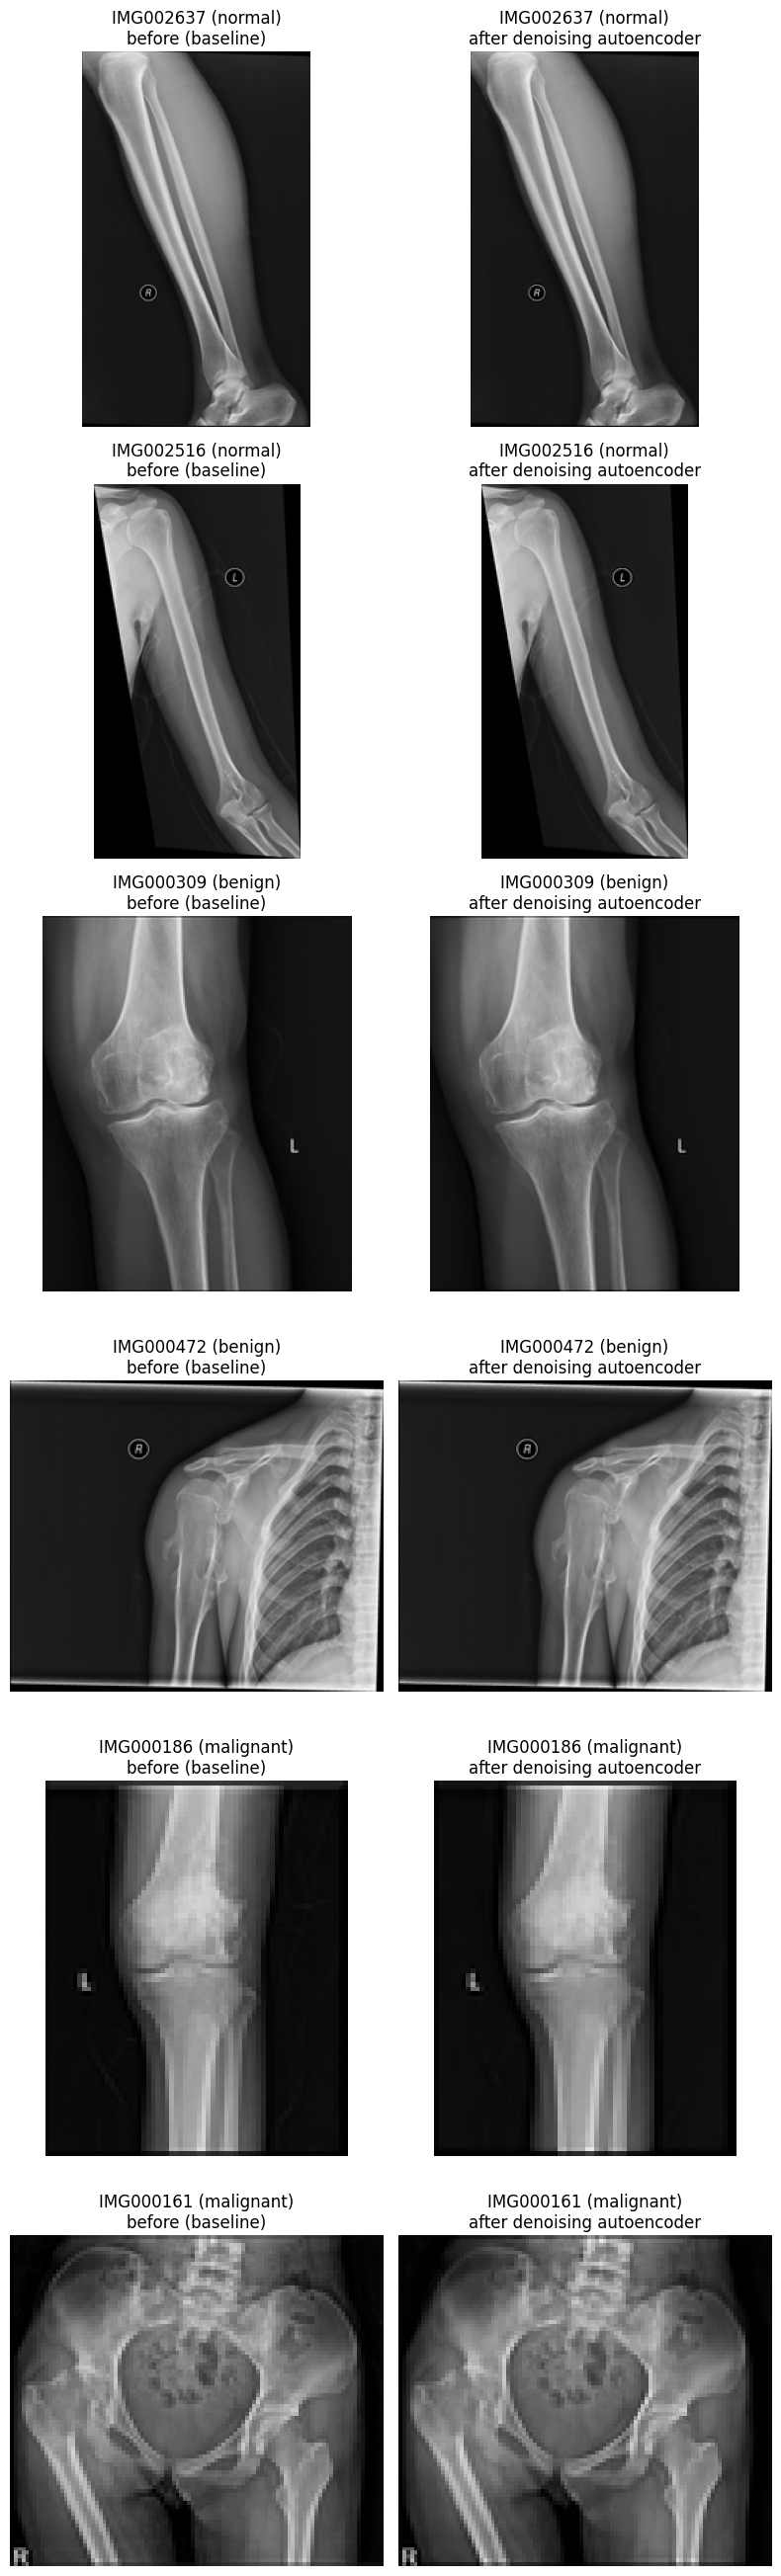

In [13]:
picks = pd.concat([images[images["group"] == group].sample(2, random_state=42)
                   for group in ["normal", "benign", "malignant"]])
titles = ["before (baseline)", "after denoising autoencoder"]

fig, axes = plt.subplots(len(picks), 2, figsize=(8, 4.4 * len(picks)))
for row, (_, pick) in zip(axes, picks.iterrows()):
    before = baseline(pick)                                    # the baseline image
    after = shrink(autoencoder(load(pick['path'])))            # denoising autoencoder on the full image, then 512 x 512
    top, bottom, left, right = xray_box(before)                # cut away the black square, so the bone is big enough to see
    for ax, picture, title in zip(row, [before, after], titles):
        ax.imshow(picture[top:bottom, left:right], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{pick['image']} ({pick['group']})\n{title}")
        ax.axis("off")

plt.tight_layout()
plt.show()

## Measuring functions
The same functions as in the classical notebooks.
- PSNR and SSIM: how much the image changed (higher = less change). Measured on the X-ray only, not the black square.
- CII: how much more the tumor stands out from the ring around it. Above 1 = it stands out more.

In [14]:
def tumor_mask(name):
    annotation = json.loads((ANNOTATIONS / (name + ".json")).read_text())
    scale = SIZE[0] / annotation["imageWidth"]                 # the outline was drawn on the 2440 x 2440 image
    mask = np.zeros((SIZE[1], SIZE[0]), dtype=np.uint8)
    for shape in annotation["shapes"]:
        if shape["shape_type"] == "polygon":                   # the outline (the rectangles are only boxes)
            points = np.round(np.array(shape["points"]) * scale).astype(np.int32)
            cv2.fillPoly(mask, [points], 1)
    return mask == 1                                           # True inside the tumor


def ring_around(tumor, before):
    kernel = np.ones((2 * RING + 1, 2 * RING + 1), dtype=np.uint8)
    bigger = cv2.dilate(tumor.astype(np.uint8), kernel) == 1   # the tumor made RING pixels bigger
    return bigger & ~tumor & (before > BLACK)                  # the ring: not the tumor, not the black background


def contrast(image, tumor, ring):
    t = image[tumor].mean()                                    # tumor brightness
    r = image[ring].mean()                                     # ring brightness
    return abs(t - r) / (t + r)                                # abs: a tumor can be darker or brighter than the bone


def cii(before, after, tumor, ring):
    if tumor.sum() == 0 or ring.sum() == 0:
        return np.nan                                          # cannot be measured
    contrast_before = contrast(before, tumor, ring)
    if contrast_before == 0:
        return np.nan                                          # cannot divide by 0
    return contrast(after, tumor, ring) / contrast_before


def psnr_ssim(before, after):
    top, bottom, left, right = xray_box(before)                # the X-ray only
    a, b = before[top:bottom, left:right], after[top:bottom, left:right]
    return peak_signal_noise_ratio(a, b, data_range=255), structural_similarity(a, b, data_range=255)

## Measuring functions at full size
The same tumor outline and ring, but on the 2440 x 2440 image: the outline is not made smaller, and the ring is 48 pixels wide (the same area as the 10-pixel ring at 512 x 512), as in the classical `*_full_size_scores` notebooks.

In [15]:
def tumor_mask_full(name, size):
    annotation = json.loads((ANNOTATIONS / (name + ".json")).read_text())
    scale = size[1] / annotation["imageWidth"]                 # 1.0: the outline was drawn on the 2440 x 2440 image
    mask = np.zeros(size, dtype=np.uint8)
    for shape in annotation["shapes"]:
        if shape["shape_type"] == "polygon":                   # the outline (the rectangles are only boxes)
            points = np.round(np.array(shape["points"]) * scale).astype(np.int32)
            cv2.fillPoly(mask, [points], 1)
    return mask == 1                                           # True inside the tumor


def ring_around_full(tumor, before):
    kernel = np.ones((2 * RING_FULL + 1, 2 * RING_FULL + 1), dtype=np.uint8)
    bigger = cv2.dilate(tumor.astype(np.uint8), kernel) == 1   # the tumor made RING_FULL pixels bigger
    return bigger & ~tumor & (before > BLACK)                  # the ring: not the tumor, not the black background

## Make every image
For every image: denoising autoencoder on the full image, then 512 x 512, then saved as PNG in the Drive folder `BTXRD/BTXRD_autoencoder_512`.
While the full-size result is there, its **full-size scores** are measured too (the full image after the denoising autoencoder against the original full image) and saved as one line per image in `BTXRD/BTXRD_autoencoder_512_full_size_scores.csv`. So the method runs only once.
Images that are already done are skipped, so after a disconnect this continues where it stopped.

In [16]:
def png_path(item):
    return OUT_DIR / item["split"] / item["label"] / (item["image"] + ".png")


def scored_images():
    if not FULL_SCORES.exists():
        return set()
    return set(pd.read_csv(FULL_SCORES)["image"])             # images that already have their full-size scores


scored = scored_images()
todo = [item for _, item in images.iterrows() if not png_path(item).exists() or item["image"] not in scored]
print(len(images) - len(todo), "images already done,", len(todo), "to do")

start = time.time()
for n, item in enumerate(todo, start=1):
    raw = load(item["path"])                                   # the original X-ray at full size
    full = autoencoder(raw)                                    # denoising autoencoder on the full image (2440 x 2440)
    after = shrink(full)                                       # then 512 x 512

    psnr, ssim = psnr_ssim(raw, full)                          # full-size scores: the full image after the method vs the original
    row = {"image": item["image"], "label": item["label"], "PSNR": psnr, "SSIM": ssim, "CII": np.nan}
    if item["label"] == "tumor":
        tumor = tumor_mask_full(item["image"], raw.shape)
        row["CII"] = cii(raw, full, tumor, ring_around_full(tumor, raw))
    pd.DataFrame([row]).to_csv(FULL_SCORES, mode="a", header=not FULL_SCORES.exists(), index=False)   # one line per image, in Drive

    target = png_path(item)
    target.parent.mkdir(parents=True, exist_ok=True)
    temporary = target.with_suffix(".tmp")
    Image.fromarray(after).save(temporary, format="PNG")
    os.replace(temporary, target)                              # renamed only when complete, so a half-written image is never kept

    if n % 100 == 0 or n == len(todo):
        minutes_left = (time.time() - start) / n * (len(todo) - n) / 60
        print(f"{n} of {len(todo)} done, about {minutes_left:.0f} minutes left")

done = sum(1 for _, item in images.iterrows() if png_path(item).exists())
scored = scored_images()
print(done, "of", len(images), "images are in", OUT_DIR, "|", len(scored & set(images["image"])), "have full-size scores")
assert done == len(images) and set(images["image"]) <= scored, "not all images are done: run this cell again"

0 images already done, 3723 to do
100 of 3723 done, about 33 minutes left
200 of 3723 done, about 33 minutes left
300 of 3723 done, about 32 minutes left
400 of 3723 done, about 31 minutes left
500 of 3723 done, about 30 minutes left
600 of 3723 done, about 29 minutes left
700 of 3723 done, about 28 minutes left
800 of 3723 done, about 28 minutes left
900 of 3723 done, about 27 minutes left
1000 of 3723 done, about 26 minutes left
1100 of 3723 done, about 25 minutes left
1200 of 3723 done, about 23 minutes left
1300 of 3723 done, about 22 minutes left
1400 of 3723 done, about 21 minutes left
1500 of 3723 done, about 20 minutes left
1600 of 3723 done, about 19 minutes left
1700 of 3723 done, about 19 minutes left
1800 of 3723 done, about 18 minutes left
1900 of 3723 done, about 17 minutes left
2000 of 3723 done, about 16 minutes left
2100 of 3723 done, about 15 minutes left
2200 of 3723 done, about 14 minutes left
2300 of 3723 done, about 13 minutes left
2400 of 3723 done, about 12 minu

## Make the zip
Puts all images in `BTXRD_autoencoder_512.zip` (`BTXRD_autoencoder_512/split/label/name.png`), the same layout as `BTXRD_512.zip`, and also copies it to Drive.

In [17]:
with zipfile.ZipFile(NEW_ZIP, "w") as new_zip:                 # "w": makes a new zip (an old one with the same name is replaced)
    for _, item in images.iterrows():
        source = OUT_DIR / item["split"] / item["label"] / (item["image"] + ".png")
        new_zip.write(source, f"{NAME}/{item['split']}/{item['label']}/{item['image']}.png")

shutil.copy(NEW_ZIP, DRIVE / NEW_ZIP.name)                     # also keep the zip in Google Drive
print(len(images), "images saved in", NEW_ZIP, "and in", DRIVE / NEW_ZIP.name)

3723 images saved in /content/BTXRD_autoencoder_512.zip and in /content/drive/MyDrive/BTXRD/BTXRD_autoencoder_512.zip


## Check the new zip
Counts the images in each folder, checks that all are 512 x 512 gray images, and that every image is in the same split and label as in `BTXRD_512.zip`.

In [18]:
with zipfile.ZipFile(NEW_ZIP) as new_zip:
    files = [name for name in new_zip.namelist() if name.endswith(".png")]
    sizes, modes = Counter(), Counter()
    for name in files:
        image = Image.open(new_zip.open(name))
        sizes[image.size] += 1
        modes[image.mode] += 1                                 # L = gray

for folder, count in sorted(Counter(name.rsplit("/", 1)[0] for name in files).items()):
    print(folder, count)
print("Sizes:", dict(sizes), "| modes:", dict(modes))
new_names = {name.removeprefix(NAME + "/").removesuffix(".png") for name in files}
print("Same images, split and label as BTXRD_512.zip:", new_names == old_names)
print("Zip size:", round(NEW_ZIP.stat().st_size / 1e6), "MB")

BTXRD_autoencoder_512/test/normal 280
BTXRD_autoencoder_512/test/tumor 279
BTXRD_autoencoder_512/train/normal 1306
BTXRD_autoencoder_512/train/tumor 1300
BTXRD_autoencoder_512/validation/normal 280
BTXRD_autoencoder_512/validation/tumor 278
Sizes: {(512, 512): 3723} | modes: {'L': 3723}
Same images, split and label as BTXRD_512.zip: True
Zip size: 63 MB


## Measure every image at 512 x 512
PSNR, SSIM and CII of every image in the new zip against its baseline image, as in the classical notebooks. CII is only for tumor images.

In [19]:
rows = []
with zipfile.ZipFile(NEW_ZIP) as new_zip:
    for _, item in images.iterrows():
        before = baseline(item)                                # the baseline image
        after = np.array(Image.open(io.BytesIO(new_zip.read(f"{NAME}/{item['split']}/{item['label']}/{item['image']}.png"))))

        psnr, ssim = psnr_ssim(before, after)
        row = {"image": item["image"], "label": item["label"], "PSNR": psnr, "SSIM": ssim, "CII": np.nan}
        if item["label"] == "tumor":
            tumor = tumor_mask(item["image"])
            row["CII"] = cii(before, after, tumor, ring_around(tumor, before))
        rows.append(row)

scores = pd.DataFrame(rows)
print(len(scores), "images measured")

3723 images measured


## Results at 512 x 512
The middle value (median) of each score: the image after the denoising autoencoder compared with the baseline image. CII only counts the tumor images.

In [20]:
scores[["PSNR", "SSIM", "CII"]].median().round(3)

,0
PSNR,42.843
SSIM,0.993
CII,1.000


## Results at full size
The middle value (median) of each score at full size: the full image after the denoising autoencoder compared with the original full image. CII only counts the tumor images.

In [21]:
full_scores = pd.read_csv(FULL_SCORES).drop_duplicates("image", keep="last")   # one line per image (a disconnect can repeat one)
full_scores = full_scores[full_scores["image"].isin(images["image"])]
print(len(full_scores), "images with full-size scores")
assert len(full_scores) == len(images)
full_scores[["PSNR", "SSIM", "CII"]].median().round(3)

3723 images with full-size scores


,0
PSNR,35.429
SSIM,0.930
CII,1.001


## Download the zip and the full-size scores